## **Activity 1** Scenario: Animal Grouping (K-Means Clustering) You have data on various animals based on their weight and height, and you want to see if they naturally form groups (e.g., small, medium, large animals).

In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
small_animals=np.random.normal(loc=[5,20],scale=[1,5],size=(20,2))
medium_animals=np.random.normal(loc=[50,80],scale=[10,15],size=(20,2))
large_animals=np.random.normal(loc=[300,150],scale=[50,25],size=(20,2))

In [3]:
X_animals=pd.DataFrame(np.vstack([small_animals,medium_animals,large_animals]),
                       columns=['Weight_kg','Height_cm'])


In [4]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X_animals)
X_scaled_df=pd.DataFrame(X_scaled,columns=X_animals.columns)

In [5]:
X_scaled_df.head()

,Weight_kg,Height_cm
0,-0.846383,-1.148828
1,-0.845239,-1.001016
2,-0.851919,-1.157358
3,-0.838182,-1.068244
4,-0.853702,-1.088252


In [6]:
kmeans=KMeans(n_clusters=3,random_state=42,n_init=100)
kmeans.fit(X_scaled_df)

KMeans(n_clusters=3, n_init=100, random_state=42)

In [7]:
X_animals['Cluster']=kmeans.labels_

In [8]:
X_animals.head()

,Weight_kg,Height_cm,Cluster
0,5.496714,19.308678,2
1,5.647689,27.615149,2
2,4.765847,18.829315,2
3,6.579213,23.837174,2
4,4.530526,22.712800,2


In [9]:
X_animals.tail()

,Weight_kg,Height_cm,Cluster
55,204.061439,149.337153,1
56,303.011510,211.581053,1
57,290.381952,157.538684,1
58,298.264412,120.783049,1
59,357.141141,168.798326,1


In [10]:
X_animals['Cluster'].value_counts().sort_index()

,count
Cluster,
0,20
1,20
2,20


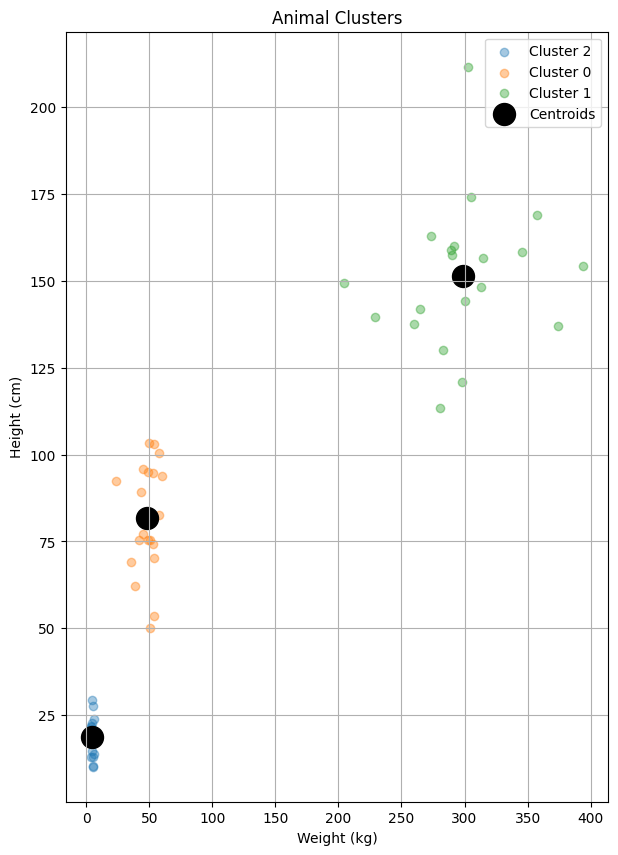

In [11]:
centroid_original=scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(7,10))
for cluster in X_animals['Cluster'].unique():
  data=X_animals[X_animals['Cluster']==cluster]
  plt.scatter(
      x=data['Weight_kg'],
      y=data['Height_cm'],
      label=f'Cluster {cluster}',
      alpha=0.4
  )
plt.scatter(
    x=centroid_original[:,0],
    y=centroid_original[:,1],
    label=f'Centroids',
    s=250,
    color='black'
)

plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title('Animal Clusters')
plt.legend()
plt.grid(True)
plt.show()

In K-Means Clustering centroid is the mean of all the points that it represents. Intutively each centroid can be thought of as a centralized representation of a particular cluster of the data.

## **Activity 2** Scenario: Grouping Students by Study Habits (Hierarchical Clustering) You have data on students’ weekly study hours and average sleep hours, and you want to find natural groupings of study habits.

In [12]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage
import matplotlib.pyplot as  plt

In [13]:
np.random.seed(42)

In [14]:
X_students=pd.DataFrame({
    'Study_Hours_Week':np.random.randint(5,40,50),
    'Sleep_Hours_Night':np.random.uniform(4,9,50).round(1)}
)

In [15]:
sum(X_students['Sleep_Hours_Night']>7)

19

In [16]:
X_students.loc[X_students['Study_Hours_Week']>30,
               'Sleep_Hours_Night']=np.random.uniform(4,
                                                      6,sum(X_students['Study_Hours_Week']>30))

X_students.loc[X_students['Study_Hours_Week']<10,
               'Sleep_Hours_Night']=np.random.uniform(7,9,
                                                      sum(X_students['Study_Hours_Week']<10))

In [17]:
print('Students Habit Data (first 5 rows)')
X_students.head()

Students Habit Data (first 5 rows)


,Study_Hours_Week,Sleep_Hours_Night
0,33,4.95074
1,19,6.00000
2,12,8.60000
3,25,7.60000
4,23,5.60000


In [18]:
Z=linkage(X_students,method='ward')

In [19]:
Z

array([[1.00000000e+01, 2.50000000e+01, 5.09771633e-02, 2.00000000e+00],
       [4.30000000e+01, 4.60000000e+01, 8.00492452e-02, 2.00000000e+00],
       [2.20000000e+01, 3.70000000e+01, 1.29152576e-01, 2.00000000e+00],
       [3.50000000e+01, 4.40000000e+01, 2.25892355e-01, 2.00000000e+00],
       [3.00000000e+00, 2.70000000e+01, 3.00000000e-01, 2.00000000e+00],
       [2.00000000e+00, 3.90000000e+01, 3.00000000e-01, 2.00000000e+00],
       [3.00000000e+01, 5.10000000e+01, 3.25368223e-01, 3.00000000e+00],
       [1.20000000e+01, 1.50000000e+01, 3.71365812e-01, 2.00000000e+00],
       [8.00000000e+00, 9.00000000e+00, 5.00000000e-01, 2.00000000e+00],
       [1.10000000e+01, 1.90000000e+01, 9.00000000e-01, 2.00000000e+00],
       [0.00000000e+00, 4.70000000e+01, 9.34966695e-01, 2.00000000e+00],
       [2.00000000e+01, 3.10000000e+01, 1.00000000e+00, 2.00000000e+00],
       [1.00000000e+00, 3.20000000e+01, 1.00498756e+00, 2.00000000e+00],
       [5.00000000e+00, 1.30000000e+01, 1.00498756e

In [23]:
hc=AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)
hc.fit(X_students)
X_students['Cluster']=hc.labels_


In [21]:
X_students.head()

,Study_Hours_Week,Sleep_Hours_Night,Cluster
0,33,4.95074,2
1,19,6.00000,0
2,12,8.60000,1
3,25,7.60000,0
4,23,5.60000,0


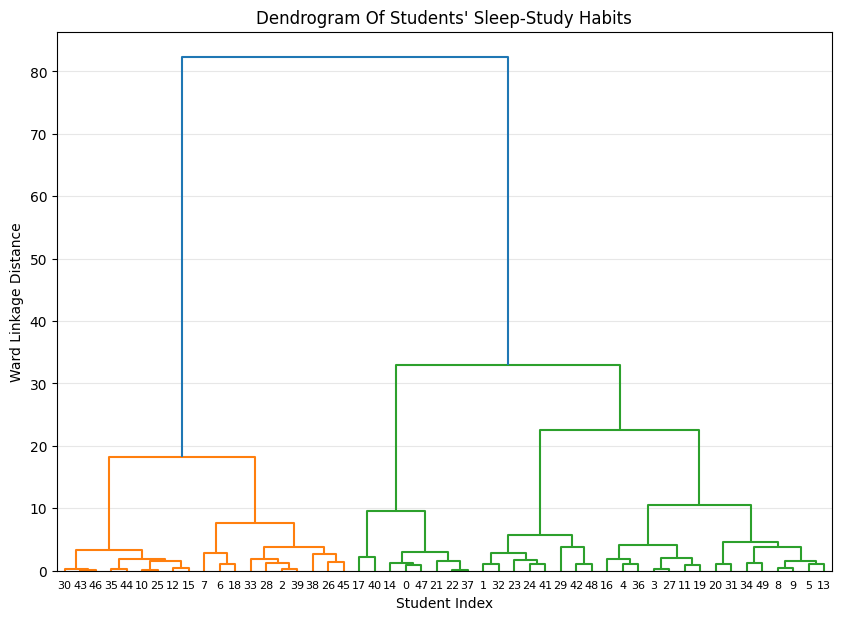

In [22]:
plt.figure(figsize=(10,7))

dendrogram(
    Z,
    labels=X_students.index.astype(str).to_list(),
    leaf_rotation=00
)

plt.title('Dendrogram Of Students\' Sleep-Study Habits')
plt.xlabel('Student Index')
plt.ylabel('Ward Linkage Distance')
plt.grid(axis='y',alpha=0.3)
plt.show()

We will cut the dendrogram horizontally between the student index value 20 and 26 as it results in 2 different clusters. Conceptually, they would likely be representing groups that would have arised while preparing the data, at the time when low study- high sleep and high study-low sleep trend was injected in the data. There are good chances that these groups represent the above trend.